# 🚀 Practice Day 35

**📅 Date:** 2026-10-15  
📁 Category: Phase 2 · 테이블 병합(merge/join) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice combining multiple related tables with merge() to answer questions no single table can answer alone
  (여러 개의 연관된 테이블을 merge()로 연결해서, 테이블 하나만으로는 풀 수 없는 질문에 답하는 연습)
- Find which department draws the most enrollments, which student takes the most courses, and which courses are most popular
  (어떤 학과가 가장 많은 수강신청을 받는지, 어떤 학생이 가장 많은 과목을 듣는지, 어떤 과목이 가장 인기 있는지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Fairhaven University — 학생·과목·수강신청 (3테이블) / Fairhaven University — Students, Courses & Enrollments (3 tables)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** Three related tables from a university. `students` (60 rows: student_id, student_name, major), `courses` (15 rows: course_id, course_name, department, credits), and `enrollments` (300 rows: enrollment_id, student_id → links to students, course_id → links to courses, semester). Every enrollment links to exactly one student and one course — clean, fully-linked keys with no missing values or duplicates.
(대학교의 연관된 3개 테이블입니다. `students`(60명: student_id, student_name, major), `courses`(15개: course_id, course_name, department, credits), `enrollments`(300건: enrollment_id, student_id(students와 연결), course_id(courses와 연결), semester). 모든 수강신청은 학생 1명과 과목 1개에 연결되어 있고, 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [45]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- students ---
first_names = ['Ava', 'Liam', 'Mia', 'Noah', 'Emma', 'Ethan', 'Olivia', 'Lucas', 'Sophia', 'Mason',
                'Isabella', 'Logan', 'Amelia', 'Jacob', 'Harper', 'Elijah', 'Evelyn', 'Aiden', 'Abigail', 'Carter']
last_names = ['Nguyen', 'Kim', 'Patel', 'Garcia', 'Muller', 'Rossi', 'Dubois', 'Andersson', 'Silva', 'Ivanov',
               'Chen', 'Park', 'Cohen', 'Novak', 'Haddad']

majors = ['Computer Science', 'Business', 'Biology', 'Psychology', 'Economics']
major_w = [0.24, 0.22, 0.18, 0.18, 0.18]

n_students = 60
rng2 = np.random.default_rng(11)
student_names = []
used = set()
while len(student_names) < n_students:
    name = f"{rng2.choice(first_names)} {rng2.choice(last_names)}"
    if name not in used:
        used.add(name)
        student_names.append(name)

students = pd.DataFrame({
    'student_id': [f'S{str(i).zfill(3)}' for i in range(1, n_students + 1)],
    'student_name': student_names,
    'major': rng.choice(majors, size=n_students, p=major_w)
})

# --- courses ---
courses_data = [
    ('Intro to Programming', 'Computer Science', 3),
    ('Data Structures', 'Computer Science', 4),
    ('Database Systems', 'Computer Science', 3),
    ('Marketing Principles', 'Business', 3),
    ('Financial Accounting', 'Business', 3),
    ('Organizational Behavior', 'Business', 3),
    ('Cell Biology', 'Biology', 4),
    ('Genetics', 'Biology', 4),
    ('Human Anatomy', 'Biology', 3),
    ('Intro to Psychology', 'Psychology', 3),
    ('Cognitive Science', 'Psychology', 3),
    ('Microeconomics', 'Economics', 3),
    ('Macroeconomics', 'Economics', 3),
    ('Statistics', 'Economics', 4),
    ('Calculus I', 'Mathematics', 4),
]
courses = pd.DataFrame(courses_data, columns=['course_name', 'department', 'credits'])
courses.insert(0, 'course_id', [f'C{str(i).zfill(3)}' for i in range(1, len(courses) + 1)])

# --- enrollments (every student takes 3-6 courses) ---
n_enrollments = 300
course_weight_base = rng.gamma(shape=2.0, scale=1.0, size=len(courses))
course_ids = courses['course_id'].values

enroll_pairs = set()
for sid in students['student_id']:
    n_courses = rng.integers(3, 7)
    chosen = rng.choice(course_ids, size=min(n_courses, len(course_ids)), replace=False,
                         p=course_weight_base / course_weight_base.sum())
    for cid in chosen:
        enroll_pairs.add((sid, cid))

enroll_pairs = list(enroll_pairs)
rng.shuffle(enroll_pairs)
if len(enroll_pairs) > n_enrollments:
    enroll_pairs = enroll_pairs[:n_enrollments]
else:
    while len(enroll_pairs) < n_enrollments:
        sid = rng.choice(students['student_id'].values)
        cid = rng.choice(course_ids)
        if (sid, cid) not in set(enroll_pairs):
            enroll_pairs.append((sid, cid))

semesters = ['Fall 2023', 'Spring 2024']
rows = []
for i, (sid, cid) in enumerate(enroll_pairs):
    rows.append({'enrollment_id': f'E{str(i+1).zfill(4)}', 'student_id': sid, 'course_id': cid,
                 'semester': rng.choice(semesters, p=[0.48, 0.52])})
enrollments = pd.DataFrame(rows)

print("Students:")
display(students.head())
print("\nCourses:")
display(courses.head())
print("\nEnrollments:")
display(enrollments.head())


Students:


,student_id,student_name,major
0,S001,Mia Kim,Psychology
1,S002,Elijah Andersson,Business
2,S003,Logan Ivanov,Economics
3,S004,Harper Nguyen,Psychology
4,S005,Mason Patel,Computer Science



Courses:


,course_id,course_name,department,credits
0,C001,Intro to Programming,Computer Science,3
1,C002,Data Structures,Computer Science,4
2,C003,Database Systems,Computer Science,3
3,C004,Marketing Principles,Business,3
4,C005,Financial Accounting,Business,3



Enrollments:


,enrollment_id,student_id,course_id,semester
0,E0001,S004,C005,Spring 2024
1,E0002,S038,C008,Spring 2024
2,E0003,S004,C007,Spring 2024
3,E0004,S023,C006,Spring 2024
4,E0005,S053,C003,Fall 2023


## Dataset Information

In [46]:
# Dataset Information
print("Students:", students.shape)
students.info()
print("\nCourses:", courses.shape)
courses.info()
print("\nEnrollments:", enrollments.shape)
enrollments.info()

print("\n--- Describe: Students ---")
display(students.describe(include='all'))
print("\n--- Describe: Courses ---")
display(courses.describe(include='all'))
print("\n--- Describe: Enrollments ---")
display(enrollments.describe(include='all'))


Students: (60, 3)
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    60 non-null     str  
 1   student_name  60 non-null     str  
 2   major         60 non-null     str  
dtypes: str(3)
memory usage: 1.5 KB

Courses: (15, 4)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   course_id    15 non-null     str  
 1   course_name  15 non-null     str  
 2   department   15 non-null     str  
 3   credits      15 non-null     int64
dtypes: int64(1), str(3)
memory usage: 612.0 bytes

Enrollments: (300, 4)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   enrollment_id  300 non-null    str  
 1   stu

,student_id,student_name,major
count,60,60,60
unique,60,60,5
top,S001,Mia Kim,Psychology
freq,1,1,17



--- Describe: Courses ---


,course_id,course_name,department,credits
count,15,15,15,15.000000
unique,15,15,6,NaN
top,C001,Intro to Programming,Computer Science,NaN
freq,1,1,3,NaN
mean,NaN,NaN,NaN,3.333333
std,NaN,NaN,NaN,0.487950
min,NaN,NaN,NaN,3.000000
25%,NaN,NaN,NaN,3.000000
50%,NaN,NaN,NaN,3.000000
75%,NaN,NaN,NaN,4.000000



--- Describe: Enrollments ---


,enrollment_id,student_id,course_id,semester
count,300,300,300,300
unique,300,60,15,2
top,E0001,S024,C012,Fall 2023
freq,1,7,37,151


---
# ❓ Business Questions

1. **(Analysis)** Which department received the most total enrollments across all its courses, and which the least?
   (전체 학과 중 수강신청을 가장 많이/적게 받은 학과는?)
2. **(Analysis)** Which student is enrolled in the most courses?
   (가장 많은 과목을 신청한 학생은?)
3. **(Analysis)** Which course has the highest enrollment, and which has the lowest?
   (가장 신청자가 많은/적은 과목은?)
4. **(Visualization)** Compare total enrollments across all departments.
   (학과별 총 수강신청 건수를 비교하면?)
5. **(Visualization)** Compare enrollment counts across all 15 courses.
   (15개 과목의 신청 인원을 비교하면?)

---
# 🔍 Data Cleaning Check


In [47]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== students =====")
print("Missing values")
print(students.isnull().sum())
print("\nDuplicate rows:", students.duplicated().sum())
print("\nDtypes")
print(students.dtypes)
print("\nColumn names")
print(students.columns.tolist())
obj_cols = students.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(students[obj_cols].nunique())
print()

print("===== courses =====")
print("Missing values")
print(courses.isnull().sum())
print("\nDuplicate rows:", courses.duplicated().sum())
print("\nDtypes")
print(courses.dtypes)
print("\nColumn names")
print(courses.columns.tolist())
obj_cols = courses.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(courses[obj_cols].nunique())
print()

print("===== enrollments =====")
print("Missing values")
print(enrollments.isnull().sum())
print("\nDuplicate rows:", enrollments.duplicated().sum())
print("\nDtypes")
print(enrollments.dtypes)
print("\nColumn names")
print(enrollments.columns.tolist())
obj_cols = enrollments.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(enrollments[obj_cols].nunique())
print()


===== students =====
Missing values
student_id      0
student_name    0
major           0
dtype: int64

Duplicate rows: 0

Dtypes
student_id      str
student_name    str
major           str
dtype: object

Column names
['student_id', 'student_name', 'major']

Text columns — unique counts
student_id      60
student_name    60
major            5
dtype: int64

===== courses =====
Missing values
course_id      0
course_name    0
department     0
credits        0
dtype: int64

Duplicate rows: 0

Dtypes
course_id        str
course_name      str
department       str
credits        int64
dtype: object

Column names
['course_id', 'course_name', 'department', 'credits']

Text columns — unique counts
course_id      15
course_name    15
department      6
dtype: int64

===== enrollments =====
Missing values
enrollment_id    0
student_id       0
course_id        0
semester         0
dtype: int64

Duplicate rows: 0

Dtypes
enrollment_id    str
student_id       str
course_id        str
semester        

---
# 📊 Analysis

## Question 1

**Question:** Which department received the most total enrollments across all its courses, and which the least? (수강신청을 가장 많이/적게 받은 학과는?)

**Result:** Business is highest at **75** enrollments. Mathematics is lowest at **14**.  
(가장 많은 학과는 Business 75건, 가장 적은 학과는 Mathematics 14건)

**Insight:** Business is **61** above Mathematics and **6** above the second place, Economics (**69**). The six departments add up to **300**.    
(Business는 Mathematics보다 61건, 2위 Economics(69건)보다 6건 많음. 여섯 학과를 합치면 300건)


In [48]:
# Question 1: total enrollments by department - needs merging enrollments with courses

enrollments_courses = enrollments.merge(courses, on='course_id', how='left')
merged = enrollments_courses.merge(students, on='student_id', how='left')

merged.groupby('department')['enrollment_id'].count().sort_values(ascending=False)

department
Business            75
Economics           69
Psychology          50
Biology             47
Computer Science    45
Mathematics         14
Name: enrollment_id, dtype: int64

## Question 2

**Question:** Which student is enrolled in the most courses? (가장 많은 과목을 신청한 학생은?)

**Result:** Carter Rossi (S024) is highest at **7** enrollments. Mia Kim, Sophia Rossi, Aiden Novak, and Aiden Chen are next at **6** each.  
(가장 많은 학생은 Carter Rossi(S024) 7건. 다음은 Mia Kim, Sophia Rossi, Aiden Novak, Aiden Chen이 각 6건)

**Insight:** Carter Rossi is **1** enrollment above the four students tied at **6**.  
(Carter Rossi는 6건으로 묶인 네 명보다 1건 많음)


In [49]:
# Question 2: student with the most course enrollments

merged.groupby(['student_id', 'student_name'])['enrollment_id'].count().sort_values(ascending=False).head(5)

student_id  student_name
S024        Carter Rossi    7
S001        Mia Kim         6
S041        Sophia Rossi    6
S028        Aiden Novak     6
S035        Aiden Chen      6
Name: enrollment_id, dtype: int64

## Question 3

**Question:** Which course has the highest enrollment, and which has the lowest? (신청자가 가장 많은/적은 과목은?)

**Result:** Microeconomics is highest at **37**. Data Structures is lowest at **7**. Marketing Principles and Cognitive Science are tied at **33**.  
(가장 많은 과목은 Microeconomics 37건, 가장 적은 과목은 Data Structures 7건. Marketing Principles와 Cognitive Science는 33건으로 같음)

**Insight:** Microeconomics is **30** above Data Structures. Mathematics in Q1 is **14**, and Calculus I is also **14**.  
(Microeconomics는 Data Structures보다 30건 많음. Q1의 Mathematics가 14건이고 Calculus I도 14건)


In [50]:
# Question 3: course with the highest / lowest enrollment

display(merged.groupby(['course_id', 'course_name'])['enrollment_id'].count().sort_values(ascending=False).head(5))
display(merged.groupby(['course_id', 'course_name'])['enrollment_id'].count().sort_values(ascending=True).head(5))


course_id  course_name            
C012       Microeconomics             37
C004       Marketing Principles       33
C011       Cognitive Science          33
C003       Database Systems           27
C006       Organizational Behavior    26
Name: enrollment_id, dtype: int64

course_id  course_name         
C002       Data Structures          7
C001       Intro to Programming    11
C007       Cell Biology            11
C008       Genetics                13
C015       Calculus I              14
Name: enrollment_id, dtype: int64

---
# 📈 Visualization

**Chart 1:** Bar chart — total enrollments by department (막대그래프: 학과별 총 수강신청 건수)

*Interpretation:* The bars fall from Business (**75**) to Economics (**69**), Psychology (**50**), Biology (**47**), Computer Science (**45**), and Mathematics (**14**). Mathematics is much shorter than the bar above it.  
(막대는 Business 75, Economics 69, Psychology 50, Biology 47, Computer Science 45, Mathematics 14 순으로 짧아짐. Mathematics는 바로 위 막대보다 훨씬 짧음)

---

**Chart 2:** Bar chart — enrollment count by course (막대그래프: 과목별 신청 인원)

*Interpretation:* Microeconomics is the longest bar at **37**. Marketing Principles and Cognitive Science are the next two, both **33**. Data Structures is the shortest at **7**.  
(Microeconomics가 37건으로 가장 김. 다음은 Marketing Principles와 Cognitive Science가 둘 다 33건. Data Structures가 7건으로 가장 짧음)


department
Business            75
Economics           69
Psychology          50
Biology             47
Computer Science    45
Mathematics         14
Name: enrollment_id, dtype: int64

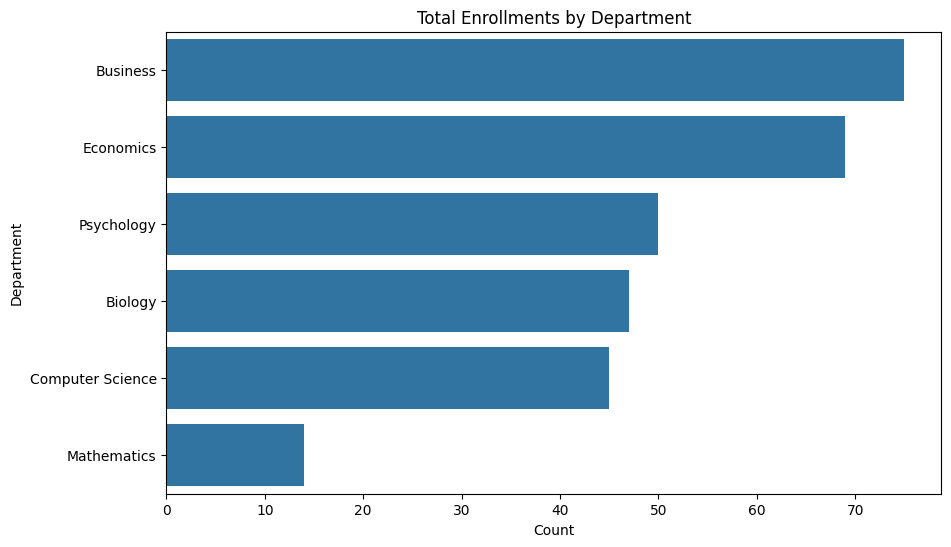

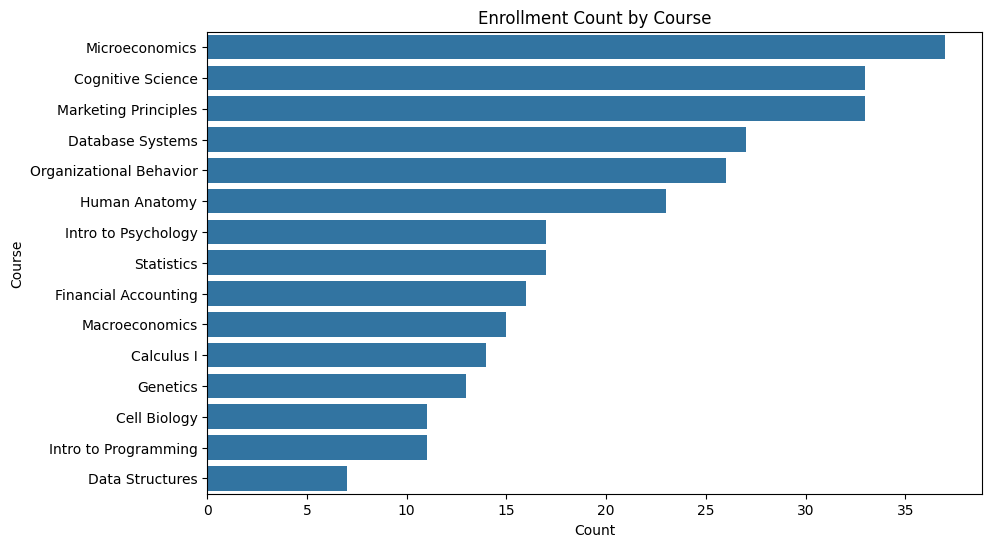

In [51]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total enrollments by department (bar)
count_by_department = merged.groupby('department')['enrollment_id'].count().sort_values(ascending=False)

display(count_by_department)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=count_by_department.values, y=count_by_department.index, ax=ax)
ax.set_title('Total Enrollments by Department')
ax.set_xlabel('Count')
ax.set_ylabel('Department')
plt.show()

# Chart 2: enrollment count by course (bar)
count_by_course = merged.groupby('course_name')['enrollment_id'].count().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=count_by_course.values, y=count_by_course.index, ax=ax)
ax.set_title('Enrollment Count by Course')
ax.set_xlabel('Count')
ax.set_ylabel('Course')
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- Business has **75** enrollments, the most of six departments. Mathematics has **14**, and that matches Calculus I at **14**.  
  (여섯 학과 중 Business가 75건으로 가장 많음. Mathematics는 14건이고, Calculus I도 14건)
- Carter Rossi (S024) is enrolled in **7** courses, one more than the four students at **6**.  
  (Carter Rossi(S024)가 7과목을 신청함. 6건인 네 명보다 1건 많음)
- Microeconomics has **37** students. Data Structures has **7**, a gap of **30**.  
  (Microeconomics 신청자는 37명. Data Structures는 7명이고 차이는 30명)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Add seats for Microeconomics (**37**) and the two courses tied at **33**, Marketing Principles and Cognitive Science.  
   (Microeconomics(37건)와 33건으로 묶인 Marketing Principles, Cognitive Science의 정원을 늘리기)
2. Check Data Structures (**7**). It is **30** below Microeconomics.  
   (Data Structures(7건)를 확인하기. Microeconomics보다 30건 적음)
3. Mathematics is one course, Calculus I, at **14**. Compare that with Business at **75** before adding another math section.  
   (Mathematics는 Calculus I 한 과목 14건. 분반을 더 열기 전에 Business 75건과 비교하기)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q2 compared the text `"student_id"` with `idxmax()`, so `loc` got `False` and raised `KeyError`.  
  (Q2에서 글자 "student_id"를 idxmax()와 비교해서 loc에 False가 들어가고 KeyError가 남)
- I expected `loc` to filter the column. It needs `merged['student_id'] == top_id`, not the column name as a string.  
  (loc가 열을 걸러 줄 거라 생각함. 열 이름 문자열이 아니라 merged['student_id'] == top_id가 필요함)  


---
# ✅ What I Learned
*Today's biggest lesson*

- A question that names a column from another table needs `merge` on the shared key first. Department is on `courses`, so enrollments join on `course_id`.  
  (다른 테이블의 열을 묻는 질문은 공통 키로 merge를 먼저 함. department는 courses에 있어서 course_id로 붙임)
- The student with the most courses is a `groupby` count sorted descending, not `idxmax` on one raw row.  
  (과목을 가장 많이 신청한 학생은 원본 한 행의 idxmax가 아니라 groupby 건수를 내림차순으로 정렬한 결과)
- `loc` compares a column with a value. `merged['student_id'] == top_id` keeps that student's rows.  
  (loc는 열과 값을 비교함. merged['student_id'] == top_id가 그 학생의 행만 남김)  


---
# 🧠 Reflection

**What was difficult?**  
Pulling the one student with the most enrollments out of the merged table.  
(합친 표에서 신청이 가장 많은 학생 한 명을 꺼내는 것)

**Why?**  
`"student_id" == idxmax()` compares two strings, so the result is one `False` instead of a row filter.  
("student_id" == idxmax()는 문자열끼리 비교라서 행 필터가 아니라 False 하나가 됨)

**How did I solve it?**  
Grouped by `student_id` and `student_name`, counted enrollments, and sorted descending. Carter Rossi is **7**.  
(student_id와 student_name으로 묶고 신청 건수를 세서 내림차순으로 정렬함. Carter Rossi가 7건)

**What would I do differently next time?**  
Sort the group counts first, and use `loc` only when I already have the id to look up.  
(그룹 건수를 먼저 정렬하고, loc는 찾을 id가 있을 때만 쓰기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Merging on `course_id` and `student_id`, then grouping, is clear. The `loc` comparison still needs a check.  
(course_id, student_id로 합친 뒤 그룹하는 것은 이해함. loc 비교는 아직 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
The merges were short. The hard part was filtering one student with `loc`.  
(merge는 짧았고, 어려운 부분은 loc로 학생 한 명을 고르는 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 36 — SQL intermediate (Round 3/5)  
  (JOIN, 서브쿼리, CASE WHEN 복습)  
